In [3]:
#this is eda for my forst project 

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings


In [5]:
df = pd.read_csv("c:/Users/pc soft/Downloads/playground-series-s6e8/train.csv")
df.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


In [6]:
df

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
691364,691364,22.0,10.78,3.25,1.57,1.65,7.71,86.0,94.0,12.89,Male,NaN,No,1
691365,691365,20.0,3.45,1.86,0.89,0.30,6.59,221.0,42.0,8.47,Female,High,No,1
691366,691366,NaN,NaN,NaN,NaN,2.06,6.16,NaN,86.0,7.79,Other,Medium,No,1
691367,691367,22.0,11.78,3.69,0.23,1.35,5.53,171.0,62.0,7.71,Other,NaN,NaN,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 691369 entries, 0 to 691368
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       691369 non-null  int64  
 1   age                      662440 non-null  float64
 2   daily_screen_time_hours  595515 non-null  float64
 3   social_media_hours       557374 non-null  float64
 4   gaming_hours             564548 non-null  float64
 5   work_study_hours         639851 non-null  float64
 6   sleep_hours              646889 non-null  float64
 7   notifications_per_day    623785 non-null  float64
 8   app_opens_per_day        610659 non-null  float64
 9   weekend_screen_time      579306 non-null  float64
 10  gender                   662335 non-null  object 
 11  stress_level             636221 non-null  object 
 12  academic_work_impact     647145 non-null  object 
 13  addicted_label           691369 non-null  int64  
dtypes: f

In [8]:
df.describe()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,addicted_label
count,691369.000000,662440.000000,595515.000000,557374.000000,564548.000000,639851.000000,646889.000000,623785.000000,610659.000000,579306.000000,691369.000000
mean,345684.000000,26.615408,7.640865,2.471038,1.459265,2.366971,6.804334,145.894900,102.636781,9.479866,0.709424
std,199581.183466,5.153162,2.721446,1.316137,0.934552,1.258797,1.234512,65.917556,48.093970,2.856006,0.454028
min,0.000000,18.000000,0.500000,0.000000,0.000000,0.000000,4.500000,20.000000,15.000000,0.510000,0.000000
25%,172842.000000,22.000000,5.480000,1.450000,0.700000,1.360000,5.780000,93.000000,64.000000,7.280000,0.000000
50%,345684.000000,27.000000,7.770000,2.310000,1.330000,2.200000,6.800000,150.000000,104.000000,9.580000,1.000000
75%,518526.000000,31.000000,9.840000,3.370000,2.090000,3.200000,7.870000,204.000000,145.000000,11.750000,1.000000
max,691368.000000,35.000000,15.000000,8.000000,4.000000,6.000000,9.000000,250.000000,180.000000,17.560000,1.000000


In [9]:
  (df['social_media_hours'] + df['gaming_hours'] > df['daily_screen_time_hours']).mean()
  (df['sleep_hours'] + df['daily_screen_time_hours'] > 24).sum()

0

In [10]:
 df.describe(include='object') 

,gender,stress_level,academic_work_impact
count,662335,636221,647145
unique,3,3,2
top,Male,High,Yes
freq,223662,220873,330566


In [11]:
miss_cols = df.columns[df.isna().any()]
res = {c: df.groupby(df[c].isna())['addicted_label'].mean() for c in miss_cols}
pd.DataFrame(res).T.rename(columns={False: 'rate_if_present', True: 'rate_if_missing'})

,rate_if_present,rate_if_missing
age,0.709251,0.713402
daily_screen_time_hours,0.709122,0.711301
social_media_hours,0.709427,0.709415
gaming_hours,0.709182,0.710505
work_study_hours,0.709326,0.710645
sleep_hours,0.709153,0.713377
notifications_per_day,0.709336,0.710242
app_opens_per_day,0.708980,0.712787
weekend_screen_time,0.709187,0.710654
gender,0.709452,0.708790


In [12]:
df[miss_cols].isna().corr()          # do NaNs co-occur?
df.isna().sum(axis=1).value_counts() # how many NaNs per row

0     269185
1     180459
2     120697
3      67328
4      32557
5      13678
6       5157
7       1676
8        477
9        136
10        18
11         1
Name: count, dtype: int64

In [13]:
df_test = pd.read_csv("c:/Users/pc soft/Downloads/playground-series-s6e8/test.csv")
df_test.head()

,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact
0,691369,30.0,9.34,NaN,0.77,4.09,7.15,153.0,16.0,NaN,Other,Medium,Yes
1,691370,NaN,NaN,1.91,NaN,1.20,8.67,239.0,148.0,10.68,Female,High,No
2,691371,26.0,8.48,3.64,NaN,3.39,7.47,106.0,123.0,NaN,Male,NaN,No
3,691372,20.0,8.37,2.99,1.69,2.53,5.45,178.0,55.0,9.88,Male,High,Yes
4,691373,25.0,8.25,4.02,1.21,2.32,8.46,63.0,86.0,10.72,Male,Low,No


In [14]:
df_submission = pd.read_csv("c:/Users/pc soft/Downloads/playground-series-s6e8/sample_submission.csv")
df_submission.head()

,id,addicted_label
0,691369,0.709424
1,691370,0.709424
2,691371,0.709424
3,691372,0.709424
4,691373,0.709424


In [15]:
df['addicted_label'].value_counts()

addicted_label
1    490474
0    200895
Name: count, dtype: int64

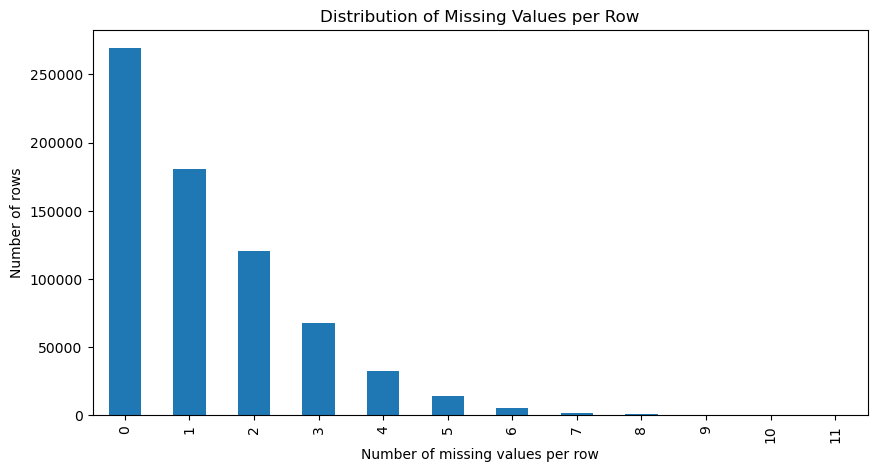

In [16]:
import matplotlib.pyplot as plt

missing_per_row = df.isna().sum(axis=1)

missing_per_row.value_counts().sort_index().plot(
    kind='bar',
    figsize=(10, 5)
)

plt.xlabel('Number of missing values per row')
plt.ylabel('Number of rows')
plt.title('Distribution of Missing Values per Row')
plt.show()

In [17]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 296302 entries, 0 to 296301
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       296302 non-null  int64  
 1   age                      279164 non-null  float64
 2   daily_screen_time_hours  263514 non-null  float64
 3   social_media_hours       248905 non-null  float64
 4   gaming_hours             236882 non-null  float64
 5   work_study_hours         268525 non-null  float64
 6   sleep_hours              273847 non-null  float64
 7   notifications_per_day    262081 non-null  float64
 8   app_opens_per_day        270597 non-null  float64
 9   weekend_screen_time      245605 non-null  float64
 10  gender                   282090 non-null  object 
 11  stress_level             276676 non-null  object 
 12  academic_work_impact     270581 non-null  object 
dtypes: float64(9), int64(1), object(3)
memory usage: 29.4+ MB


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.3f}'.format

TARGET = 'addicted_label'
num_cols = df.select_dtypes('number').columns.drop(['id', TARGET]).tolist()
cat_cols = ['gender', 'stress_level', 'academic_work_impact']

addicted_label
1    490474
0    200895
Name: count, dtype: int64
addicted_label
1   0.709
0   0.291
Name: proportion, dtype: float64


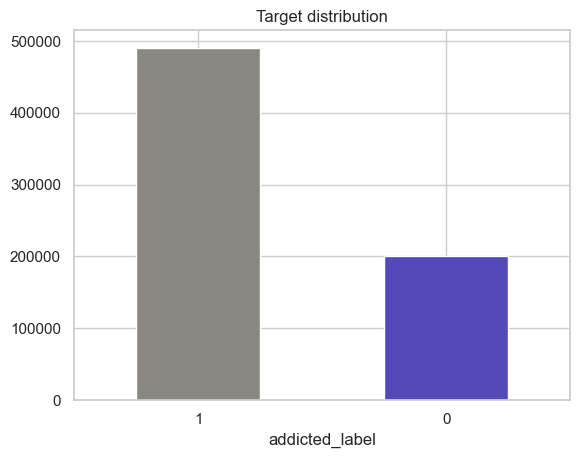

In [19]:
print(df[TARGET].value_counts())
print(df[TARGET].value_counts(normalize=True))

df[TARGET].value_counts().plot(kind='bar', color=['#888780', '#534AB7'])
plt.title('Target distribution'); plt.xticks(rotation=0); plt.show()

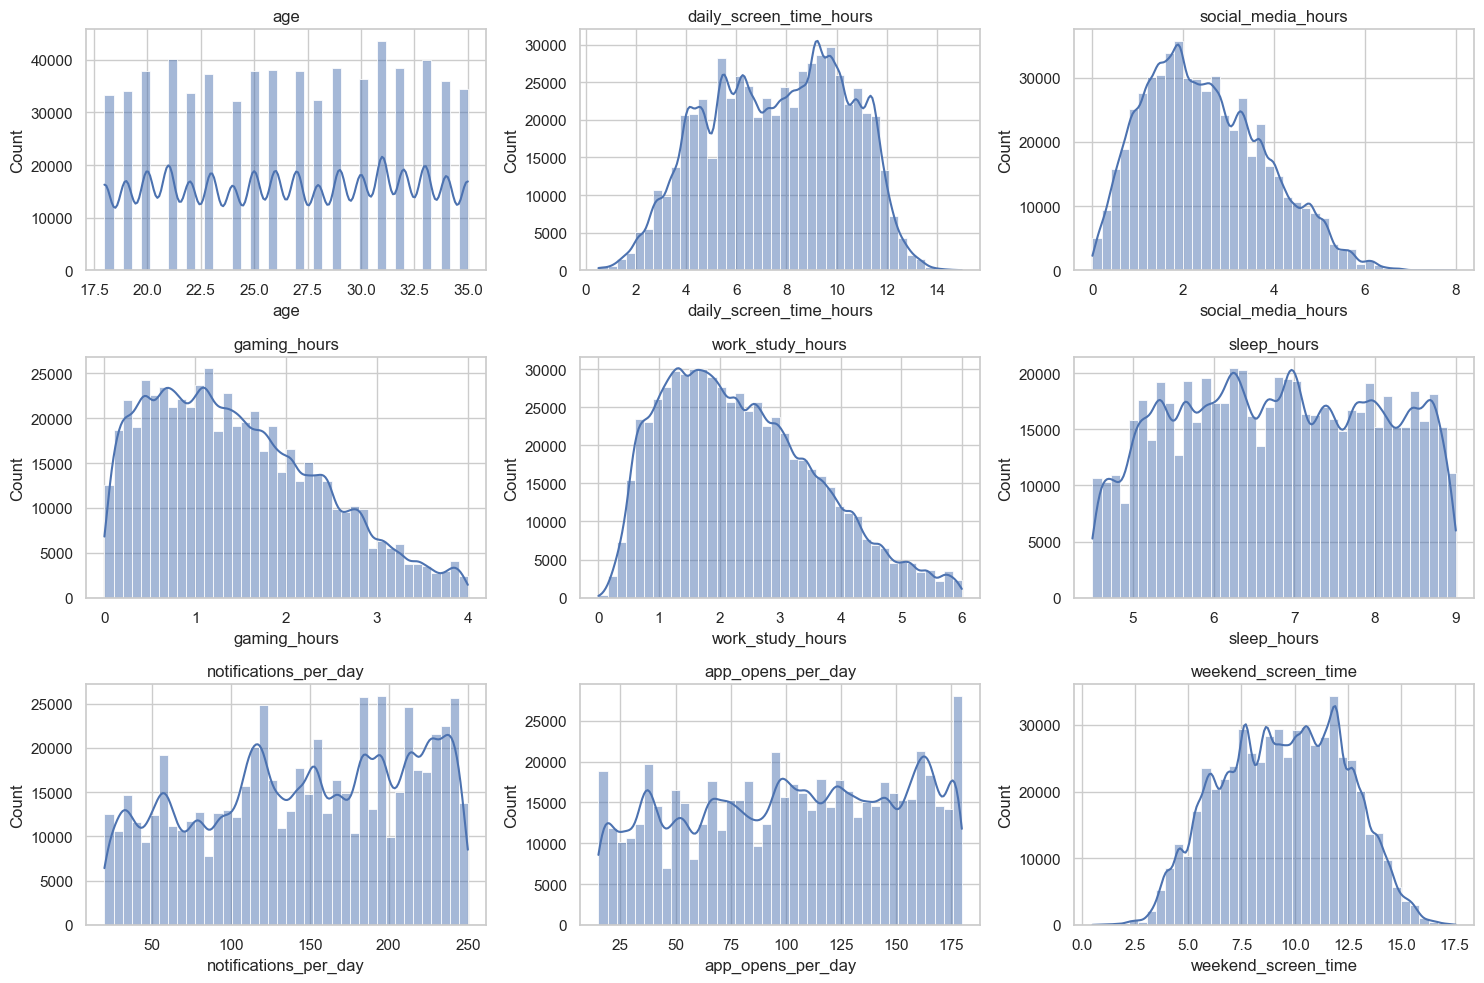

social_media_hours   0.000
gaming_hours         0.000
work_study_hours     0.000
dtype: float64


In [20]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c].dropna(), bins=40, kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

# Share of exact zeros (hours columns can legitimately be 0)
zero_cols = ['social_media_hours', 'gaming_hours', 'work_study_hours']
print((df[zero_cols] == 0).mean())

addicted_label                0       1
age                      26.583  26.629
daily_screen_time_hours   5.043   8.707
social_media_hours        1.376   2.919
gaming_hours              1.160   1.582
work_study_hours          1.873   2.570
sleep_hours               6.722   6.838
notifications_per_day   147.088 145.406
app_opens_per_day        97.871 104.593
weekend_screen_time       6.849  10.559
addicted_label                0       1
age                      27.000  27.000
daily_screen_time_hours   5.040   9.070
social_media_hours        1.290   2.820
gaming_hours              1.070   1.480
work_study_hours          1.750   2.470
sleep_hours               6.720   6.840
notifications_per_day   154.000 150.000
app_opens_per_day        99.000 109.000
weekend_screen_time       6.820  10.790


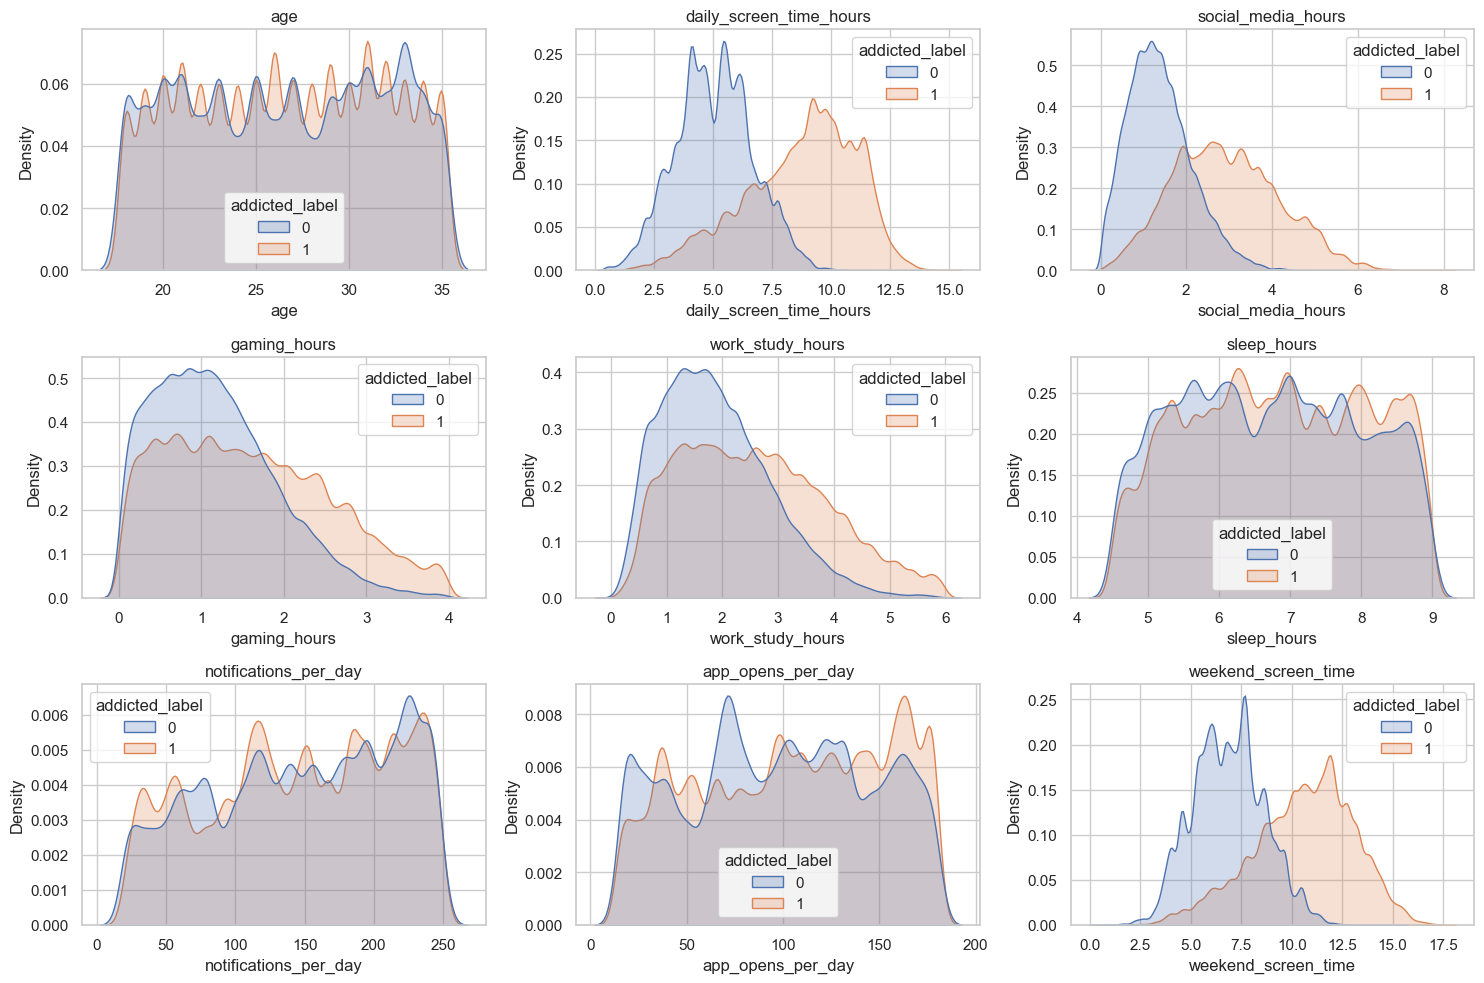

In [21]:
# Mean and median by class
print(df.groupby(TARGET)[num_cols].mean().T)
print(df.groupby(TARGET)[num_cols].median().T)

# Distribution by class
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), num_cols):
    sns.kdeplot(data=df, x=c, hue=TARGET, common_norm=False, fill=True, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

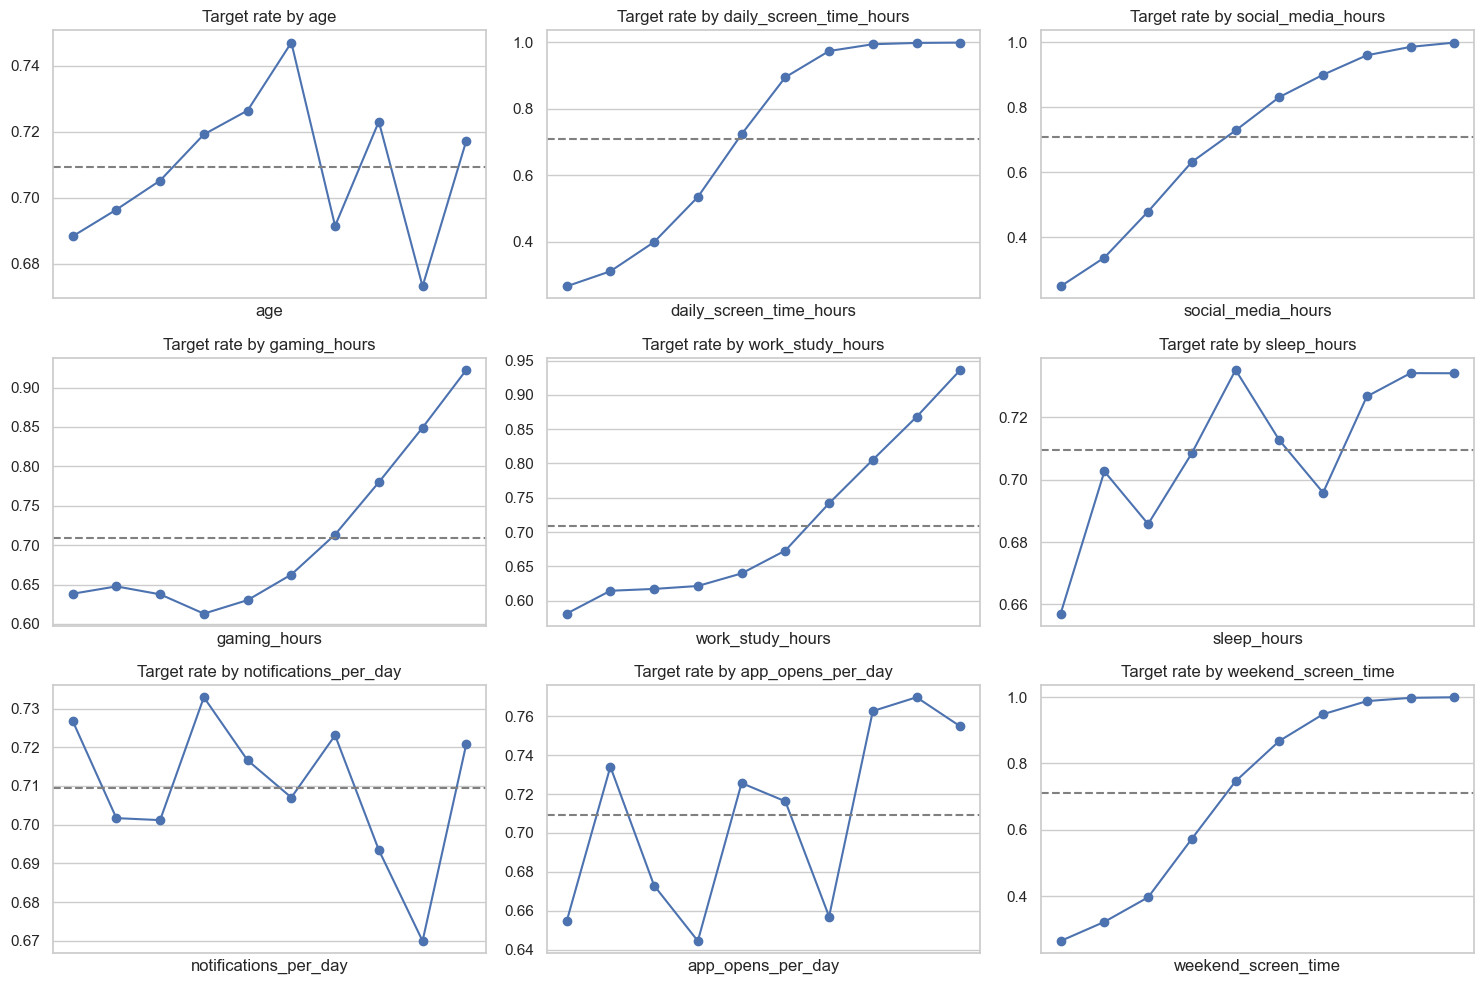

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), num_cols):
    bins = pd.qcut(df[c], q=10, duplicates='drop')
    rate = df.groupby(bins, observed=True)[TARGET].mean()
    rate.plot(marker='o', ax=ax)
    ax.axhline(df[TARGET].mean(), color='gray', linestyle='--')
    ax.set_title(f'Target rate by {c}')
    ax.set_xticks([])
plt.tight_layout(); plt.show()

In [23]:
rows = []
for c in num_cols:
    m = df[c].notna()
    auc = roc_auc_score(df.loc[m, TARGET], df.loc[m, c])
    rows.append((c, auc, abs(auc - 0.5)))

uni = pd.DataFrame(rows, columns=['feature', 'auc', 'strength']).sort_values('strength', ascending=False)
print(uni.round(4))

                   feature   auc  strength
1  daily_screen_time_hours 0.890     0.390
8      weekend_screen_time 0.881     0.381
2       social_media_hours 0.858     0.358
4         work_study_hours 0.655     0.155
3             gaming_hours 0.622     0.122
7        app_opens_per_day 0.541     0.041
5              sleep_hours 0.527     0.027
6    notifications_per_day 0.492     0.008
0                      age 0.502     0.002



--- gender ---
gender
Male      0.324
Female    0.321
Other     0.314
Missing   0.042
Name: proportion, dtype: float64

--- stress_level ---
stress_level
High      0.319
Low       0.301
Medium    0.300
Missing   0.080
Name: proportion, dtype: float64

--- academic_work_impact ---
academic_work_impact
Yes       0.478
No        0.458
Missing   0.064
Name: proportion, dtype: float64

gender
          mean    size
gender               
Female  0.704  221595
Male    0.723  223662
Missing 0.709   29034
Other   0.701  217078

stress_level
               mean    size
stress_level              
High         0.711  220873
Low          0.711  207783
Medium       0.706  207565
Missing      0.709   55148

academic_work_impact
                       mean    size
academic_work_impact              
Missing              0.709   44224
No                   0.711  316579
Yes                  0.708  330566


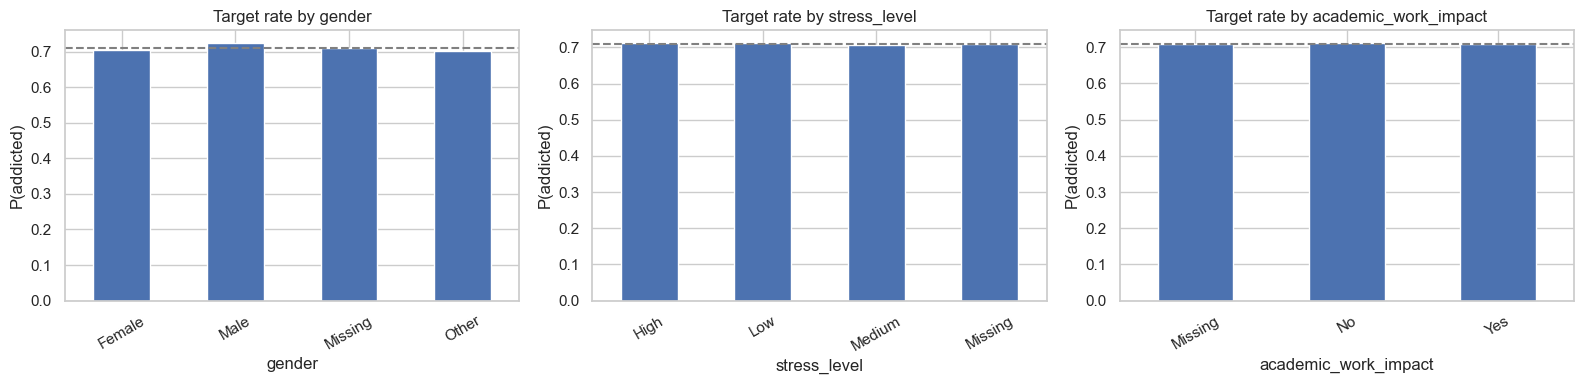

In [24]:
for c in cat_cols:
    print(f'\n--- {c} ---')
    tmp = df[c].fillna('Missing')
    print(tmp.value_counts(normalize=True).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, cat_cols):
    tmp = df.assign(**{c: df[c].fillna('Missing')})
    rate = tmp.groupby(c)[TARGET].agg(['mean', 'size'])
    print(f'\n{c}\n', rate.round(3))
    rate['mean'].plot(kind='bar', ax=ax)
    ax.axhline(df[TARGET].mean(), color='gray', linestyle='--')
    ax.set_title(f'Target rate by {c}')
    ax.set_ylabel('P(addicted)'); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

                        col  pct_missing  target_if_present  \
2        social_media_hours        0.194              0.709   
3              gaming_hours        0.183              0.709   
8       weekend_screen_time        0.162              0.709   
1   daily_screen_time_hours        0.139              0.709   
7         app_opens_per_day        0.117              0.709   
6     notifications_per_day        0.098              0.709   
10             stress_level        0.080              0.709   
4          work_study_hours        0.075              0.709   
5               sleep_hours        0.064              0.709   
11     academic_work_impact        0.064              0.709   
9                    gender        0.042              0.709   
0                       age        0.042              0.709   

    target_if_missing   diff  
2               0.709 -0.000  
3               0.711  0.001  
8               0.711  0.001  
1               0.711  0.002  
7               0.713  0.

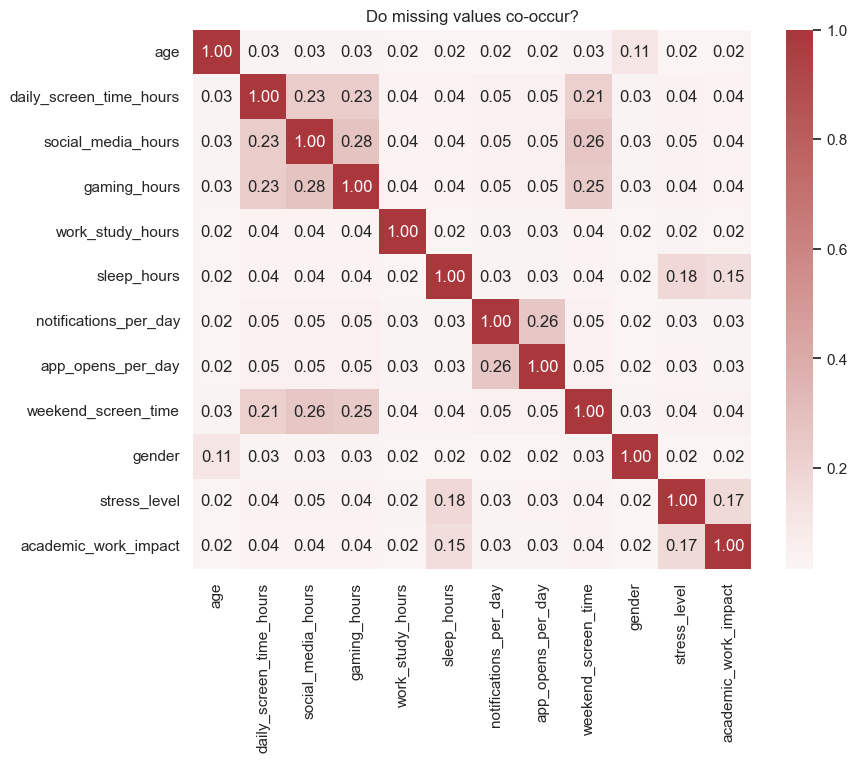

0     269185
1     180459
2     120697
3      67328
4      32557
5      13678
6       5157
7       1676
8        477
9        136
10        18
11         1
Name: count, dtype: int64


In [25]:
miss_cols = df.columns[df.isna().any()].drop('id', errors='ignore')

rows = []
for c in miss_cols:
    m = df[c].isna()
    rows.append((c, m.mean(), df.loc[~m, TARGET].mean(), df.loc[m, TARGET].mean()))

miss = pd.DataFrame(rows, columns=['col', 'pct_missing', 'target_if_present', 'target_if_missing'])
miss['diff'] = miss['target_if_missing'] - miss['target_if_present']
print(miss.sort_values('pct_missing', ascending=False).round(3))

# Co-occurrence of NaNs
plt.figure(figsize=(9, 7))
sns.heatmap(df[miss_cols].isna().corr(), annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Do missing values co-occur?'); plt.show()

print(df.isna().sum(axis=1).value_counts().sort_index())

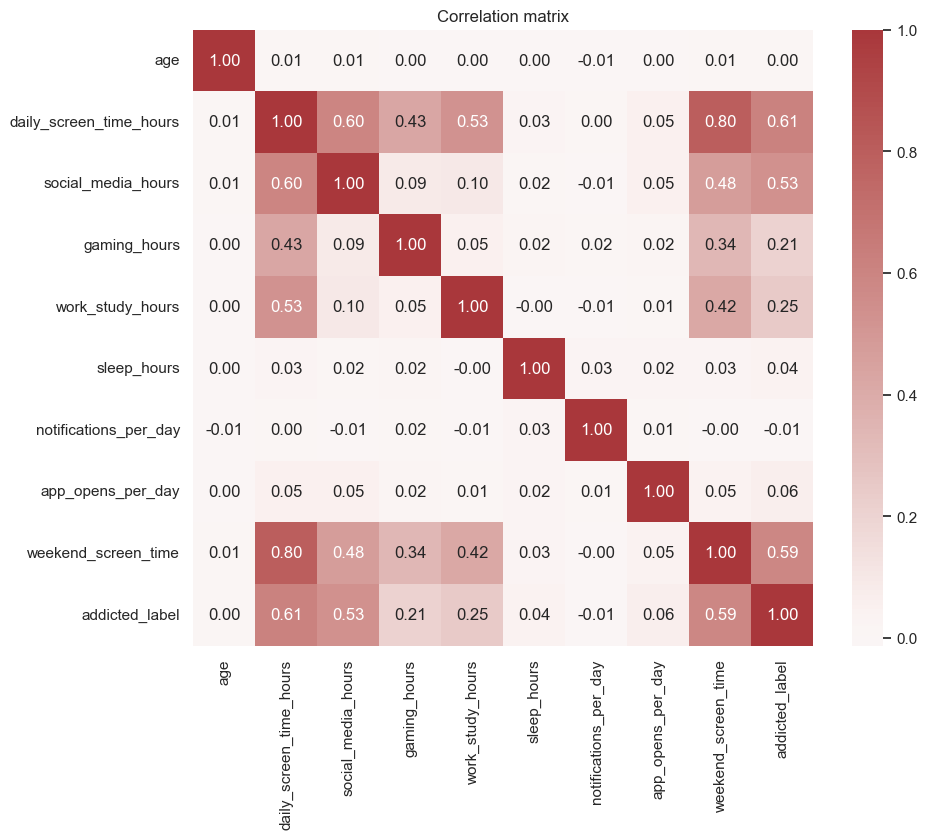

daily_screen_time_hours    0.611
weekend_screen_time        0.590
social_media_hours         0.532
work_study_hours           0.251
gaming_hours               0.205
app_opens_per_day          0.063
sleep_hours                0.043
notifications_per_day     -0.012
age                        0.004
Name: addicted_label, dtype: float64


In [26]:
corr = df[num_cols + [TARGET]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0)
plt.title('Correlation matrix'); plt.show()

print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

In [27]:
cmp = pd.DataFrame({
    'train_missing': df.drop(columns=[TARGET]).isna().mean(),
    'test_missing':  df_test.isna().mean(),
})
print(cmp.round(3))

# Distribution shift check: mean and std per numeric column
print(pd.DataFrame({
    'train_mean': df[num_cols].mean(), 'test_mean': df_test[num_cols].mean(),
    'train_std':  df[num_cols].std(),  'test_std':  df_test[num_cols].std(),
}).round(3))

                         train_missing  test_missing
id                               0.000         0.000
age                              0.042         0.058
daily_screen_time_hours          0.139         0.111
social_media_hours               0.194         0.160
gaming_hours                     0.183         0.201
work_study_hours                 0.075         0.094
sleep_hours                      0.064         0.076
notifications_per_day            0.098         0.115
app_opens_per_day                0.117         0.087
weekend_screen_time              0.162         0.171
gender                           0.042         0.048
stress_level                     0.080         0.066
academic_work_impact             0.064         0.087
                         train_mean  test_mean  train_std  test_std
age                          26.615     26.609      5.153     5.153
daily_screen_time_hours       7.641      7.641      2.721     2.726
social_media_hours            2.471      2.471      1.

In [28]:
#10. Ideas for engineered features
eng = pd.DataFrame({
    'sm_share':         df.social_media_hours / df.daily_screen_time_hours,
    'gaming_share':     df.gaming_hours / df.daily_screen_time_hours,
    'notif_per_open':   df.notifications_per_day / df.app_opens_per_day,
    'screen_per_open':  df.daily_screen_time_hours / df.app_opens_per_day,
    'weekend_diff':     df.weekend_screen_time - df.daily_screen_time_hours,
    'sleep_plus_work':  df.sleep_hours + df.work_study_hours,
})

rows = []
for c in eng.columns:
    m = eng[c].replace([np.inf, -np.inf], np.nan).notna()
    rows.append((c, roc_auc_score(df.loc[m, TARGET], eng.loc[m, c])))
print(pd.DataFrame(rows, columns=['feature', 'auc']).sort_values('auc', ascending=False).round(4))

           feature   auc
3  screen_per_open 0.698
0         sm_share 0.660
5  sleep_plus_work 0.630
4     weekend_diff 0.508
2   notif_per_open 0.467
1     gaming_share 0.388


In [29]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LogisticRegression, BayesianRidge
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier

SEED = 42
TARGET = 'addicted_label'

X = df.drop(columns=['id', TARGET])
y = df[TARGET]

num_cols = X.select_dtypes('number').columns.tolist()
cat_cols = ['gender', 'stress_level', 'academic_work_impact']

# Stratified sample for fast experiments (full data is used only for the final fit)
Xs = X.sample(100_000, random_state=SEED)
ys = y.loc[Xs.index]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [30]:
for c in cat_cols:
    print(c, '->', X[c].value_counts(dropna=False).to_dict())

gender -> {'Male': 223662, 'Female': 221595, 'Other': 217078, nan: 29034}
stress_level -> {'High': 220873, 'Low': 207783, 'Medium': 207565, nan: 55148}
academic_work_impact -> {'Yes': 330566, 'No': 316579, nan: 44224}


In [31]:
cat_pipe = Pipeline([
    ('imp', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('ohe', OneHotEncoder(handle_unknown='ignore')),
])

# A) Median only
pre_median = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), num_cols),
    ('cat', cat_pipe, cat_cols),
])

# B) Median + missing flags
pre_flags = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)),
                      ('sc', StandardScaler())]), num_cols),
    ('cat', cat_pipe, cat_cols),
])

# C) Model-based: each numeric column predicted from the others
#    (exploits daily_screen vs weekend_screen correlation of 0.80)
pre_iter = ColumnTransformer([
    ('num', Pipeline([
        ('imp', IterativeImputer(estimator=BayesianRidge(), max_iter=5,
                                 initial_strategy='median', random_state=SEED)),
        ('sc', StandardScaler())]), num_cols),
    ('cat', cat_pipe, cat_cols),
])

# D) Native NaN for tree models: leave NaN in place, ordinal-encode categories
pre_native = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                           encoded_missing_value=np.nan), cat_cols),
])

# E) Trees + median (to see if native NaN beats classic imputation)
pre_tree_median = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                           encoded_missing_value=-2), cat_cols),
])

In [32]:
def logreg():
    return LogisticRegression(max_iter=1000)

def hgb():
    return HistGradientBoostingClassifier(random_state=SEED)

experiments = {
    'LogReg + median':         Pipeline([('pre', pre_median),      ('clf', logreg())]),
    'LogReg + median + flags': Pipeline([('pre', pre_flags),       ('clf', logreg())]),
    'LogReg + iterative':      Pipeline([('pre', pre_iter),        ('clf', logreg())]),
    'HistGB + native NaN':     Pipeline([('pre', pre_native),      ('clf', hgb())]),
    'HistGB + median':         Pipeline([('pre', pre_tree_median), ('clf', hgb())]),
}

results = []
for name, pipe in experiments.items():
    t0 = time.time()
    scores = cross_val_score(pipe, Xs, ys, cv=cv, scoring='roc_auc', n_jobs=-1)
    results.append((name, scores.mean(), scores.std(), time.time() - t0))
    print(f'{name:26s} AUC = {scores.mean():.4f} ± {scores.std():.4f}  ({time.time()-t0:.0f}s)')

res = (pd.DataFrame(results, columns=['strategy', 'mean_auc', 'std', 'seconds'])
         .sort_values('mean_auc', ascending=False).reset_index(drop=True))
res

LogReg + median            AUC = 0.9111 ± 0.0014  (8s)
LogReg + median + flags    AUC = 0.9133 ± 0.0011  (6s)
LogReg + iterative         AUC = 0.9182 ± 0.0015  (9s)
HistGB + native NaN        AUC = 0.9506 ± 0.0007  (6s)
HistGB + median            AUC = 0.9498 ± 0.0007  (6s)


,strategy,mean_auc,std,seconds
0,HistGB + native NaN,0.951,0.001,5.985
1,HistGB + median,0.950,0.001,6.012
2,LogReg + iterative,0.918,0.001,8.841
3,LogReg + median + flags,0.913,0.001,5.577
4,LogReg + median,0.911,0.001,8.143


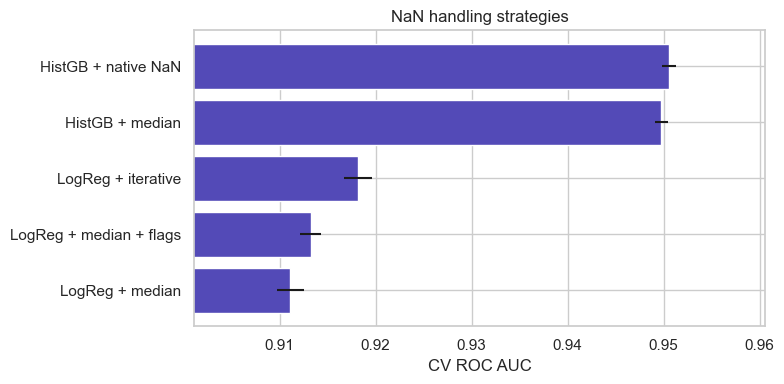

In [33]:
plt.figure(figsize=(8, 4))
plt.barh(res['strategy'][::-1], res['mean_auc'][::-1], xerr=res['std'][::-1], color='#534AB7')
plt.xlim(res['mean_auc'].min() - 0.01, res['mean_auc'].max() + 0.01)
plt.xlabel('CV ROC AUC'); plt.title('NaN handling strategies')
plt.tight_layout(); plt.savefig('nan_strategies.png', dpi=150); plt.show()

In [34]:
best = res.loc[0]
runner_up = res.loc[1]
gap = best['mean_auc'] - runner_up['mean_auc']
print(f"Best: {best['strategy']} ({best['mean_auc']:.4f})")
print(f"Gap to runner-up: {gap:.4f}  vs. fold std: {best['std']:.4f}")

Best: HistGB + native NaN (0.9506)
Gap to runner-up: 0.0008  vs. fold std: 0.0007


In [35]:
# Force the winner strategy to your winning experiment key
WINNER = 'HistGB + native NaN'
final_pipe = experiments[WINNER]

final_pipe.fit(X, y)
joblib.dump(final_pipe, 'model_step4.joblib')

# Sanity check on the test set: same columns, same missing handling
# test_proba = final_pipe.predict_proba(test.drop(columns=['id']))[:, 1]
print('Saved pipeline:', WINNER)

c:\Users\pc soft\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\pc soft\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\pc soft\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\pc soft\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\pc soft\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.Creat

Saved pipeline: HistGB + native NaN


In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer
from sklearn.ensemble import HistGradientBoostingClassifier

SEED = 42
TARGET = 'addicted_label'
X = df.drop(columns=['id', TARGET])
y = df[TARGET]

Xs = X.sample(100_000, random_state=SEED)   # same sample idea as step 4
ys = y.loc[Xs.index]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cat_cols = ['gender', 'stress_level', 'academic_work_impact']

In [37]:
def add_features(data, groups=()):
    d = data.copy()

    if 'aggregates' in groups:
        # combine the strongest, correlated columns (works even if one is missing)
        d['mean_screen'] = d[['daily_screen_time_hours', 'weekend_screen_time']].mean(axis=1)
        d['total_activity'] = d[['social_media_hours', 'gaming_hours', 'work_study_hours']].sum(axis=1, min_count=1)
        d['other_hours'] = (d['daily_screen_time_hours'] - d['social_media_hours']
                            - d['gaming_hours'] - d['work_study_hours'])

    if 'ratios' in groups:
        d['sm_share'] = d['social_media_hours'] / d['daily_screen_time_hours']
        d['gaming_share'] = d['gaming_hours'] / d['daily_screen_time_hours']
        d['screen_per_open'] = d['daily_screen_time_hours'] / d['app_opens_per_day']
        d['notif_per_open'] = d['notifications_per_day'] / d['app_opens_per_day']

    if 'differences' in groups:
        d['weekend_diff'] = d['weekend_screen_time'] - d['daily_screen_time_hours']
        d['weekend_ratio'] = d['weekend_screen_time'] / d['daily_screen_time_hours']
        d['sleep_plus_work'] = d['sleep_hours'] + d['work_study_hours']

    if 'missing' in groups:
        strong = ['daily_screen_time_hours', 'weekend_screen_time', 'social_media_hours']
        d['n_missing'] = data.isna().sum(axis=1)
        d['n_missing_strong'] = data[strong].isna().sum(axis=1)

    return d.replace([np.inf, -np.inf], np.nan)   # division by 0 becomes NaN, trees handle NaN

In [38]:
def make_pipe(groups=()):
    pre = ColumnTransformer([
        ('num', 'passthrough', make_column_selector(dtype_include=np.number)),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                               encoded_missing_value=np.nan), cat_cols),
    ])
    return Pipeline([
        ('fe', FunctionTransformer(add_features, kw_args={'groups': tuple(groups)})),
        ('pre', pre),
        ('clf', HistGradientBoostingClassifier(random_state=SEED)),
    ])

In [39]:
experiments = {
    'baseline (no new features)': [],
    '+ aggregates':               ['aggregates'],
    '+ ratios':                   ['ratios'],
    '+ differences':              ['differences'],
    '+ missing counts':           ['missing'],
    '+ aggregates + differences': ['aggregates', 'differences'],
    '+ all groups':               ['aggregates', 'ratios', 'differences', 'missing'],
}

rows = []
for name, groups in experiments.items():
    s = cross_val_score(make_pipe(groups), Xs, ys, cv=cv, scoring='roc_auc', n_jobs=-1)
    rows.append((name, s.mean(), s.std()))
    print(f'{name:30s} AUC = {s.mean():.4f} ± {s.std():.4f}')

res5 = pd.DataFrame(rows, columns=['features', 'mean_auc', 'std'])
base = res5.loc[0, 'mean_auc']
res5['gain_vs_baseline'] = res5['mean_auc'] - base
res5 = res5.sort_values('mean_auc', ascending=False).reset_index(drop=True)
res5

baseline (no new features)     AUC = 0.9506 ± 0.0007
+ aggregates                   AUC = 0.9516 ± 0.0005
+ ratios                       AUC = 0.9510 ± 0.0006
+ differences                  AUC = 0.9501 ± 0.0005
+ missing counts               AUC = 0.9504 ± 0.0005
+ aggregates + differences     AUC = 0.9513 ± 0.0005
+ all groups                   AUC = 0.9518 ± 0.0006


,features,mean_auc,std,gain_vs_baseline
0,+ all groups,0.952,0.001,0.001
1,+ aggregates,0.952,0.000,0.001
2,+ aggregates + differences,0.951,0.000,0.001
3,+ ratios,0.951,0.001,0.000
4,baseline (no new features),0.951,0.001,0.000
5,+ missing counts,0.950,0.000,-0.000
6,+ differences,0.950,0.001,-0.000


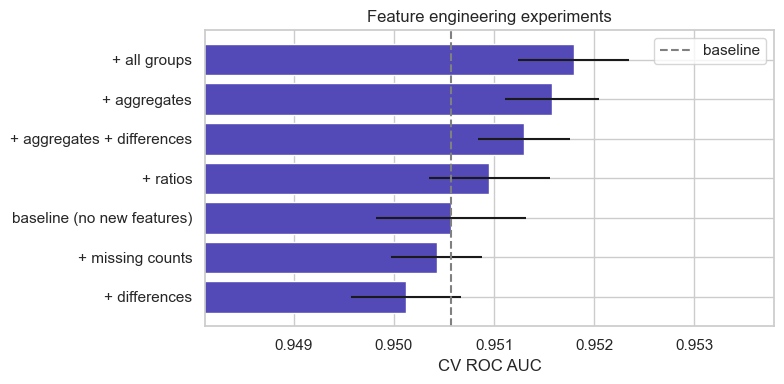

In [40]:
plt.figure(figsize=(8, 4))
plt.barh(res5['features'][::-1], res5['mean_auc'][::-1], xerr=res5['std'][::-1], color='#534AB7')
plt.axvline(base, color='gray', linestyle='--', label='baseline')
plt.xlim(res5['mean_auc'].min() - 0.002, res5['mean_auc'].max() + 0.002)
plt.xlabel('CV ROC AUC'); plt.title('Feature engineering experiments')
plt.legend(); plt.tight_layout()
plt.savefig('feature_experiments.png', dpi=150); plt.show()

In [41]:
best = res5.loc[0]
print(f"Best: {best['features']}  gain: {best['gain_vs_baseline']:+.4f}  std: {best['std']:.4f}")

Best: + all groups  gain: +0.0012  std: 0.0006


In [42]:
from sklearn.inspection import permutation_importance

chosen = experiments['+ all groups']
pipe = make_pipe(chosen).fit(Xs, ys)

# Importance on the engineered table (use a small subset so it's fast)
Xe = pipe.named_steps['fe'].transform(Xs.sample(20_000, random_state=SEED))
Xe_pre = pipe.named_steps['pre'].transform(Xe)
yy = ys.loc[Xe.index]

imp = permutation_importance(pipe.named_steps['clf'], Xe_pre, yy,
                             scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=-1)

names = (Xe.select_dtypes('number').columns.tolist() + cat_cols)
(pd.Series(imp.importances_mean, index=names)
   .sort_values(ascending=False).head(12).round(4))

mean_screen               0.105
social_media_hours        0.056
daily_screen_time_hours   0.033
weekend_screen_time       0.018
sm_share                  0.011
app_opens_per_day         0.010
notifications_per_day     0.009
other_hours               0.009
total_activity            0.008
work_study_hours          0.006
gaming_share              0.005
gaming_hours              0.002
dtype: float64

In [43]:
BEST_GROUPS = experiments['+ all groups']   # replace with the winning setup from your table

final_pipe = make_pipe(BEST_GROUPS).fit(X, y)    # train on ALL the data this time
joblib.dump(final_pipe, 'model_step5.joblib')
print('Saved with feature groups:', BEST_GROUPS) 

Saved with feature groups: ['aggregates', 'ratios', 'differences', 'missing']


In [44]:
from sklearn.model_selection import cross_val_score

base_scores = cross_val_score(make_pipe([]), Xs, ys, cv=cv, scoring='roc_auc', n_jobs=-1)
agg_scores  = cross_val_score(make_pipe(['aggregates']), Xs, ys, cv=cv, scoring='roc_auc', n_jobs=-1)

diff = agg_scores - base_scores
print(diff.round(4))                       # one difference per fold
print('mean gain:', diff.mean().round(4), '| folds where it wins:', (diff > 0).sum(), 'of 5')

[0.0009 0.0012 0.0013 0.0015 0.0001]
mean gain: 0.001 | folds where it wins: 5 of 5


In [45]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OrdinalEncoder, FunctionTransformer
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

SEED = 42


In [46]:
GROUPS = ('aggregates',)    # the winner from step 5

In [47]:
def make_pipe(clf):
    pre = ColumnTransformer([
        ('num', 'passthrough', make_column_selector(dtype_include=np.number)),
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                               encoded_missing_value=np.nan), cat_cols),
    ])
    return Pipeline([
        ('fe', FunctionTransformer(add_features, kw_args={'groups': GROUPS})),
        ('pre', pre),
        ('clf', clf),
    ])

In [48]:
models = {
    'HistGB': HistGradientBoostingClassifier(random_state=SEED),

    'LightGBM': LGBMClassifier(
        n_estimators=500, learning_rate=0.05, num_leaves=31,
        random_state=SEED, verbose=-1),

    'XGBoost': XGBClassifier(
        n_estimators=500, learning_rate=0.05, max_depth=6,
        tree_method='hist', eval_metric='auc',
        random_state=SEED, verbosity=0),

    'CatBoost': CatBoostClassifier(
        iterations=500, learning_rate=0.05, depth=6,
        eval_metric='AUC', random_seed=SEED, verbose=0),
}

In [49]:
rows, fold_scores = [], {}

for name, clf in models.items():
    t0 = time.time()
    s = cross_val_score(make_pipe(clf), Xs, ys, cv=cv, scoring='roc_auc', n_jobs=1)
    fold_scores[name] = s
    rows.append((name, s.mean(), s.std(), time.time() - t0))
    print(f'{name:10s} AUC = {s.mean():.4f} ± {s.std():.4f}  ({time.time()-t0:.0f}s)')

res6 = (pd.DataFrame(rows, columns=['model', 'mean_auc', 'std', 'seconds'])
          .sort_values('mean_auc', ascending=False).reset_index(drop=True))
res6

HistGB     AUC = 0.9516 ± 0.0005  (27s)
LightGBM   AUC = 0.9558 ± 0.0006  (36s)
XGBoost    AUC = 0.9550 ± 0.0005  (52s)
CatBoost   AUC = 0.9496 ± 0.0008  (84s)


,model,mean_auc,std,seconds
0,LightGBM,0.956,0.001,35.743
1,XGBoost,0.955,0.000,51.886
2,HistGB,0.952,0.000,27.398
3,CatBoost,0.950,0.001,84.052


In [50]:
best = res6.loc[0, 'model']
for name in res6['model'][1:]:
    d = fold_scores[best] - fold_scores[name]
    print(f'{best} vs {name:9s} mean gain {d.mean():+.4f} | wins {(d > 0).sum()} of 5 folds')

LightGBM vs XGBoost   mean gain +0.0007 | wins 5 of 5 folds
LightGBM vs HistGB    mean gain +0.0042 | wins 5 of 5 folds
LightGBM vs CatBoost  mean gain +0.0062 | wins 5 of 5 folds


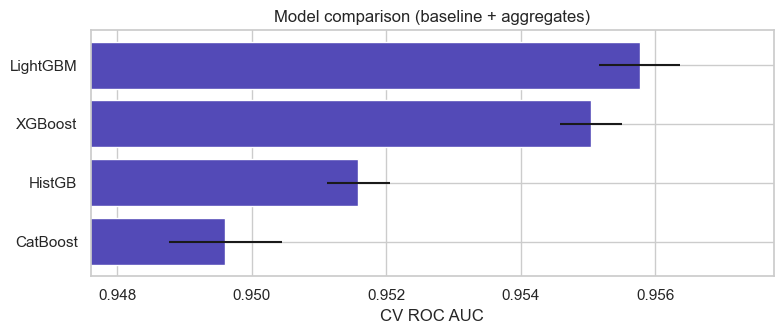

In [51]:
plt.figure(figsize=(8, 3.5))
plt.barh(res6['model'][::-1], res6['mean_auc'][::-1], xerr=res6['std'][::-1], color='#534AB7')
plt.xlim(res6['mean_auc'].min() - 0.002, res6['mean_auc'].max() + 0.002)
plt.xlabel('CV ROC AUC'); plt.title('Model comparison (baseline + aggregates)')
plt.tight_layout(); plt.savefig('reports/figures/model_comparison.png', dpi=150); plt.show()

In [52]:
from sklearn.model_selection import cross_val_predict

oof = {}
for name in res6['model'][:3]:
    oof[name] = cross_val_predict(make_pipe(models[name]), Xs, ys, cv=cv,
                                  method='predict_proba', n_jobs=1)[:, 1]

oof = pd.DataFrame(oof)
print(oof.corr().round(3))

          LightGBM  XGBoost  HistGB
LightGBM     1.000    0.994   0.992
XGBoost      0.994    1.000   0.990
HistGB       0.992    0.990   1.000


In [53]:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

ranks = oof.apply(rankdata)
print('single best:', roc_auc_score(ys, oof[res6.loc[0, 'model']]).round(4))
print('rank-average of top 3:', roc_auc_score(ys, ranks.mean(axis=1)).round(4))

single best: 0.9558
rank-average of top 3: 0.9549


In [54]:
top2 = res6['model'][:2].tolist()
print('Carry forward to tuning:', top2)

final_pipe = make_pipe(models[res6.loc[0, 'model']]).fit(X, y)   # full data this time
joblib.dump(final_pipe, 'model_step6.joblib')

Carry forward to tuning: ['LightGBM', 'XGBoost']


['model_step6.joblib']

In [55]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [56]:
import numpy as np
import pandas as pd

import joblib
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

SEED = 42
GROUPS = ('aggregates',)
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [57]:
def prepare(data):
    d = add_features(data, groups=GROUPS)
    for c in cat_cols:
        d[c] = d[c].astype('category')        # LightGBM handles categories + NaN natively
    return d

Xs_fe = prepare(Xs)
cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)   # 3 folds = faster

In [58]:
def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 200, 1200),
        'learning_rate':     trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 15, 127),
        'max_depth':         trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 200),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'subsample_freq':    1,
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        'random_state': SEED, 'verbose': -1,
    }
    model = LGBMClassifier(**params)
    scores = cross_val_score(model, Xs_fe, ys, cv=cv_tune, scoring='roc_auc')
    return scores.mean()

In [59]:
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print('Best AUC:', round(study.best_value, 4))
print(study.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Best AUC: 0.9572
{'n_estimators': 879, 'learning_rate': 0.0984467472027515, 'num_leaves': 28, 'max_depth': 4, 'min_child_samples': 48, 'subsample': 0.842376904813641, 'colsample_bytree': 0.6686700252708864, 'reg_alpha': 0.004677566649165441, 'reg_lambda': 0.0017270561772247807}


In [60]:
def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 200, 1200),
        'learning_rate':     trial.suggest_float('learning_rate', 0.02, 0.15, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 15, 127),
        'max_depth':         trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 200),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'subsample_freq':    1,
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
        'random_state': SEED, 'verbose': -1,
    }
    model = LGBMClassifier(**params)
    scores = cross_val_score(model, Xs_fe, ys, cv=cv_tune, scoring='roc_auc')
    return scores.mean()

In [61]:
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print('Best AUC:', round(study.best_value, 4))
print(study.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Best AUC: 0.9572
{'n_estimators': 879, 'learning_rate': 0.0984467472027515, 'num_leaves': 28, 'max_depth': 4, 'min_child_samples': 48, 'subsample': 0.842376904813641, 'colsample_bytree': 0.6686700252708864, 'reg_alpha': 0.004677566649165441, 'reg_lambda': 0.0017270561772247807}


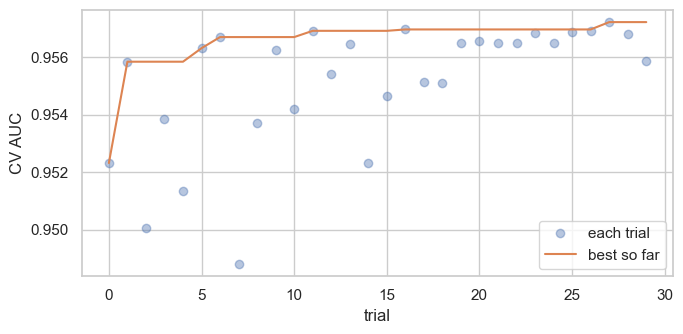

{'reg_alpha': 0.2967435244815403, 'subsample': 0.24682459349811273, 'num_leaves': 0.16945835153399944, 'max_depth': 0.1253172444438199, 'reg_lambda': 0.06906050455670147, 'n_estimators': 0.04299046346568809, 'min_child_samples': 0.027538084634753657, 'learning_rate': 0.015530710729797241, 'colsample_bytree': 0.006536522655587153}


In [62]:
hist = study.trials_dataframe()[['number', 'value']]
hist['best_so_far'] = hist['value'].cummax()

plt.figure(figsize=(7, 3.5))
plt.plot(hist['number'], hist['value'], 'o', alpha=0.4, label='each trial')
plt.plot(hist['number'], hist['best_so_far'], '-', label='best so far')
plt.xlabel('trial'); plt.ylabel('CV AUC'); plt.legend(); plt.tight_layout()
plt.savefig('reports/figures/optuna_progress.png', dpi=150); plt.show()

print(optuna.importance.get_param_importances(study))

In [63]:
cv_check = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)   # different seed

default_lgbm = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31,
                              random_state=SEED, verbose=-1)
tuned_lgbm = LGBMClassifier(**study.best_params, random_state=SEED, verbose=-1,
                            **({'subsample_freq': 1} if 'subsample_freq' not in study.best_params else {}))

s_default = cross_val_score(default_lgbm, Xs_fe, ys, cv=cv_check, scoring='roc_auc')
s_tuned   = cross_val_score(tuned_lgbm,   Xs_fe, ys, cv=cv_check, scoring='roc_auc')

d = s_tuned - s_default
print(f'default: {s_default.mean():.4f} | tuned: {s_tuned.mean():.4f}')
print(f'gain: {d.mean():+.4f} | tuned wins {(d > 0).sum()} of 5 folds')

default: 0.9556 | tuned: 0.9577
gain: +0.0022 | tuned wins 5 of 5 folds


In [64]:
cv_full = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
X_fe = prepare(X)

full_scores = cross_val_score(tuned_lgbm, X_fe, y, cv=cv_full, scoring='roc_auc')
print(f'Tuned LightGBM, full data: {full_scores.mean():.4f} ± {full_scores.std():.4f}')

Tuned LightGBM, full data: 0.9626 ± 0.0004


In [65]:
import shap
print(shap.__version__)

0.46.0


c:\Users\pc soft\anaconda3\Lib\site-packages\shap\explainers\_tree.py:448: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn('LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray')


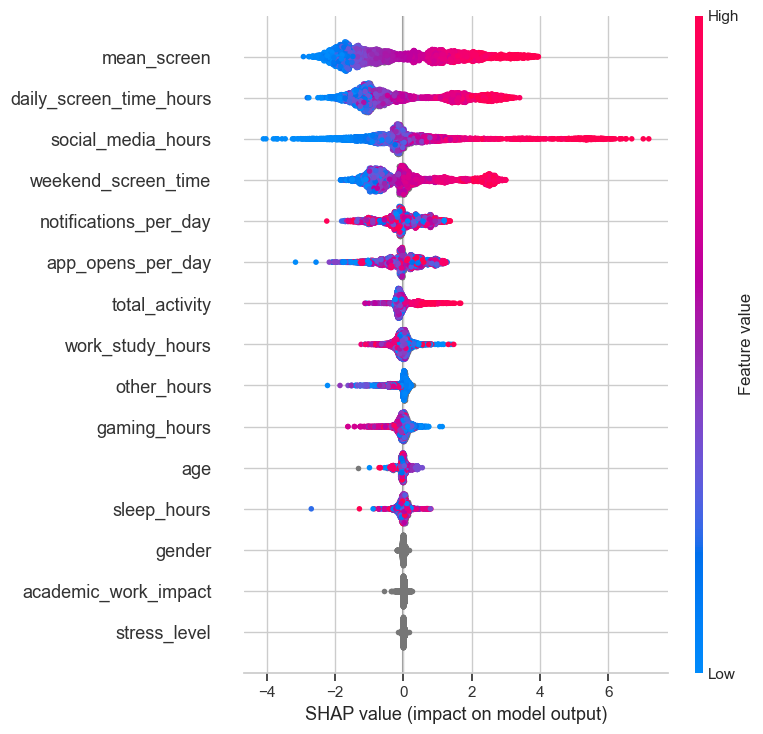

In [66]:
import shap

model = LGBMClassifier(**study.best_params, random_state=SEED, verbose=-1,
                       **({'subsample_freq': 1} if 'subsample_freq' not in study.best_params else {}))
model.fit(X_fe, y)

sample = X_fe.sample(5000, random_state=SEED)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(sample)
sv = shap_values[1] if isinstance(shap_values, list) else shap_values   # handles version differences

shap.summary_plot(sv, sample, show=False)
plt.tight_layout(); plt.savefig('reports/figures/shap_summary.png', dpi=150, bbox_inches='tight'); plt.show()

In [67]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6,
                    tree_method='hist', enable_categorical=True,
                    random_state=SEED, verbosity=0)

p_lgb = cross_val_predict(tuned_lgbm, Xs_fe, ys, cv=cv_check, method='predict_proba')[:, 1]
p_xgb = cross_val_predict(xgb,        Xs_fe, ys, cv=cv_check, method='predict_proba')[:, 1]

blend = (rankdata(p_lgb) + rankdata(p_xgb)) / 2
print('LightGBM alone:', round(roc_auc_score(ys, p_lgb), 4))
print('XGBoost alone: ', round(roc_auc_score(ys, p_xgb), 4))
print('Rank blend:    ', round(roc_auc_score(ys, blend), 4))

LightGBM alone: 0.9577
XGBoost alone:  0.955
Rank blend:     0.9572


In [68]:
df_test = pd.read_csv("c:/Users/pc soft/Downloads/playground-series-s6e8/test.csv") 
df_submission = pd.read_csv("c:/Users/pc soft/Downloads/playground-series-s6e8/sample_submission.csv")

print(df_test.shape, df_submission.shape)
print(df_submission.head())
print(set(X.columns) - set(df_test.columns))   # should print set() = nothing missing

(296302, 13) (296302, 2)
       id  addicted_label
0  691369           0.709
1  691370           0.709
2  691371           0.709
3  691372           0.709
4  691373           0.709
set()


In [80]:
def prepare_test(data):
    d = add_features(data, groups=GROUPS)
    for c in cat_cols:
        d[c] = pd.Categorical(d[c], categories=X_fe[c].cat.categories)
    return d[X_fe.columns]            # same columns, same order as training

df_test = prepare_test(df_test.drop(columns=['id']))
print(df_test.shape, X_fe.shape)      # same number of columns

KeyError: "['id'] not found in axis"

In [78]:
test_proba = final_model.predict_proba(df_test)[:, 1]

submission = pd.DataFrame({
    df_submission.columns[0]: df_test['id'],
    df_submission.columns[1]: test_proba,
})
submission.to_csv('submission.csv', index=False)

print(submission.head())
print(submission.shape, '| same columns as sample:', list(submission.columns) == list(df_submission.columns))
print(submission.iloc[:, 1].describe())    # values should be between 0 and 1

KeyError: 'id'

In [81]:
import os, joblib
import pandas as pd

# 1. Get a trained model
if os.path.exists('model_final_lgbm.joblib'):
    final_model = joblib.load('model_final_lgbm.joblib')
    print('Loaded saved model')
else:
    final_model = LGBMClassifier(**study.best_params, random_state=SEED, verbose=-1,
                                 **({'subsample_freq': 1} if 'subsample_freq' not in study.best_params else {}))
    final_model.fit(X_fe, y)
    joblib.dump(final_model, 'model_final_lgbm.joblib')
    print('Trained and saved model')

# 2. Prepare the test data: keep the ids separate from the features
test_ids = df_test['id']
test_features = df_test.drop(columns=['id'])

test_fe = add_features(test_features, groups=GROUPS)
for c in cat_cols:
    test_fe[c] = pd.Categorical(test_fe[c], categories=X_fe[c].cat.categories)
test_fe = test_fe[X_fe.columns]          # same columns, same order as training

# 3. Predict and build the submission
test_proba = final_model.predict_proba(test_fe)[:, 1]

submission = pd.DataFrame({
    df_submission.columns[0]: test_ids,
    df_submission.columns[1]: test_proba,
})
submission.to_csv('submission.csv', index=False)

print(submission.shape, '| expected:', df_submission.shape)
print(submission.head())
print(submission.isna().sum().sum(), 'missing values')
print(submission.iloc[:, 1].describe().round(3))

Loaded saved model


KeyError: 'id'

In [76]:
print(df_test.columns.tolist())
print(df_submission.head())

['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time', 'gender', 'stress_level', 'academic_work_impact', 'mean_screen', 'total_activity', 'other_hours']
       id  addicted_label
0  691369           0.709
1  691370           0.709
2  691371           0.709
3  691372           0.709
4  691373           0.709
